# Evaluación fuera de línea del motor · Primera chamba

**Pregunta:** ¿qué representación del texto recomienda mejores vacantes para un perfil: TF-IDF o un modelo de
embeddings multilingüe? ¿Y le gana a recomendar al azar o lo más popular?

**Diseño (PRD §7):**
- **Consultas:** 1,000 vacantes del catálogo (110,928) convertidas en **perfiles sintéticos**: puesto + categorías de
  habilidad + nivel, que es lo que una persona escribiría en el formulario de la app.
- **Etiquetas que el modelo no ve:** salen de campos estructurados, no del texto.
  - *Con título:* 2 = mismo puesto normalizado (`titulo_norm`); 1 = comparte categoría de habilidad **e** industria; 0 = el resto.
  - *Solo estructural:* 1 = comparte categoría de habilidad e industria; 0 = el resto. Sirve para medir cuánto se
    beneficia TF-IDF de copiar las palabras del título.
- **Sin fugas:** del ranking de cada consulta se quita su vacante de origen y todas las que comparten su descripción
  exacta (`grupo_plantilla`).
- **Métricas:** nDCG@10 (relevancia graduada) y Recall@10 acotado (aciertos del nivel máximo entre min(10, relevantes)),
  con intervalos al 95 % por bootstrap sobre las consultas.
- **Métodos:** TF-IDF (título + 70 palabras, y descripción completa), `paraphrase-multilingual-MiniLM-L12-v2`,
  `multilingual-e5-small`, y dos líneas base: **aleatorio** y **popularidad** (las vacantes más vistas).
- **Prueba entre idiomas:** 200 perfiles traducidos al español con MarianMT (`Helsinki-NLP/opus-mt-en-es`).

**Regla de decisión, fijada antes de ver los resultados:** la app atiende a usuarios mexicanos que escriben en español,
así que se elige el modelo con **mayor nDCG@10 (con título) con perfiles en español**. Los resultados en inglés y con
etiquetas estructurales sirven para confirmar que ese modelo no pierde en lo demás.

In [1]:
import os, sys, time, gc, warnings
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import transformers; transformers.logging.set_verbosity_error()
from primera_chamba import evaluacion as ev

pd.set_option("display.precision", 3)
N_CONSULTAS, N_IDIOMAS, SEMILLA = 1000, 200, 0

## 1. Catálogo y consultas

In [2]:
t0 = time.time()
df = ev.cargar_catalogo()
habilidades = ev.nombres_habilidades()
etiquetas = ev.Etiquetas(df)
grupo = df["grupo_plantilla"].to_numpy()
consultas = ev.elegir_consultas(df, n=N_CONSULTAS, semilla=SEMILLA)
perfiles = [ev.perfil(f, habilidades) for _, f in consultas.iterrows()]
print(f"Catálogo: {len(df):,} vacantes · consultas: {len(consultas):,} con {consultas['titulo_norm'].nunique():,} puestos distintos · {time.time()-t0:.1f} s")
print("Nivel de las consultas:", consultas["nivel"].fillna("sin dato").value_counts().to_dict())
for p in perfiles[:5]: print("  ·", p)

Catálogo: 110,928 vacantes · consultas: 1,000 con 684 puestos distintos · 0.9 s
Nivel de las consultas: {'Mid-Senior level': 349, 'Entry level': 309, 'sin dato': 203, 'Associate': 94, 'Director': 30, 'Executive': 10, 'Internship': 5}
  · lpn licensed practical nurse. Skills: Health Care Provider. Experience level: entry level.
  · mechanical engineer. Skills: Engineering. Experience level: entry level.
  · product manager. Skills: Product Management. Experience level: mid-senior level.
  · mechanical engineer. Skills: Engineering. Experience level: associate.
  · program manager. Skills: Information Technology, Project Management. Experience level: mid-senior level.


### ¿Cuántas vacantes relevantes tiene cada consulta?
Si una consulta tuviera miles de relevantes, cualquier método acertaría por suerte; por eso se compara contra el azar.

In [3]:
conteos = []
for _, f in consultas.iterrows():
    t, e, x = etiquetas.de(f)
    conteos.append({"mismo puesto (2)": int((t[~x] == 2).sum()), "estructural (1)": int((e[~x] == 1).sum())})
conteos = pd.DataFrame(conteos)
resumen = conteos.describe(percentiles=[.25, .5, .75]).T[["min", "25%", "50%", "75%", "max"]]
resumen["% del catálogo (mediana)"] = 100 * resumen["50%"] / len(df)
resumen

,min,25%,50%,75%,max,% del catálogo (mediana)
mismo puesto (2),5.0,11.00,29.0,79.0,1373.0,0.026
estructural (1),0.0,240.75,813.5,2330.0,12333.0,0.733


## 2. Rankings de los seis métodos

In [4]:
tops, tiempos = {}, {}
tops["aleatorio"] = ev.tops_aleatorio(consultas, grupo, semilla=SEMILLA)
tops["popularidad"] = ev.tops_popularidad(consultas, grupo, df["vistas"].to_numpy())
for clave in ["tfidf", "tfidf_completo", "minilm", "e5"]:
    t0 = time.time()
    r = ev.Ranker(clave)
    tops[clave] = ev.tops_modelo(r, perfiles, consultas, grupo)
    tiempos[clave] = time.time() - t0
    del r; gc.collect()
print({k: f"{v:.1f} s" for k, v in tiempos.items()}, "(incluye cargar el índice y el modelo)")
res = ev.evaluar(tops, consultas, etiquetas)

{'tfidf': '3.1 s', 'tfidf_completo': '4.2 s', 'minilm': '7.4 s', 'e5': '7.0 s'} (incluye cargar el índice y el modelo)


## 3. Resultados

In [5]:
NOMBRES = {"aleatorio": "Aleatorio", "popularidad": "Popularidad", "tfidf": "TF-IDF (70 palabras)",
           "tfidf_completo": "TF-IDF (descripción completa)", "minilm": "MiniLM multilingüe", "e5": "e5-small multilingüe"}
METRICAS = {"ndcg_titulo": "nDCG@10 · con título", "recall_titulo": "Recall@10 · con título",
            "ndcg_estructural": "nDCG@10 · estructural", "recall_estructural": "Recall@10 · estructural"}

def tabla(res):
    partes = []
    for m, nombre in METRICAS.items():
        b = ev.bootstrap(res, m)
        partes.append(b.apply(lambda r: f"{r.media:.3f} [{r.ic_inf:.3f}, {r.ic_sup:.3f}]", axis=1).rename(nombre))
    t = pd.concat(partes, axis=1)
    t.index = [NOMBRES[i] for i in t.index]
    return t.sort_values("nDCG@10 · con título", ascending=False)

print("Media [intervalo al 95 % por bootstrap, 2,000 remuestreos de las consultas]")
tabla(res)

Media [intervalo al 95 % por bootstrap, 2,000 remuestreos de las consultas]


,nDCG@10 · con título,Recall@10 · con título,nDCG@10 · estructural,Recall@10 · estructural
TF-IDF (70 palabras),"0.442 [0.423, 0.460]","0.422 [0.402, 0.441]","0.196 [0.179, 0.213]","0.196 [0.179, 0.213]"
TF-IDF (descripción completa),"0.407 [0.389, 0.425]","0.378 [0.360, 0.396]","0.169 [0.153, 0.184]","0.172 [0.157, 0.188]"
MiniLM multilingüe,"0.365 [0.346, 0.382]","0.312 [0.294, 0.329]","0.199 [0.181, 0.216]","0.199 [0.182, 0.216]"
e5-small multilingüe,"0.361 [0.342, 0.379]","0.313 [0.294, 0.331]","0.210 [0.193, 0.228]","0.207 [0.190, 0.225]"
Aleatorio,"0.008 [0.007, 0.010]","0.001 [0.000, 0.001]","0.022 [0.018, 0.026]","0.022 [0.018, 0.025]"
Popularidad,"0.002 [0.001, 0.003]","0.001 [0.000, 0.002]","0.004 [0.002, 0.005]","0.003 [0.002, 0.004]"


### Diferencias pareadas
Las mismas consultas pasan por todos los métodos, así que la comparación justa es la diferencia **consulta por
consulta**. `P(a > b)` es la fracción de remuestreos en que gana `a`.

In [6]:
pares = [("e5", "minilm"), ("e5", "tfidf"), ("minilm", "tfidf"), ("tfidf", "tfidf_completo")]
filas = []
for m in ["ndcg_titulo", "ndcg_estructural"]:
    for a, b in pares:
        d, lo, hi, p = ev.diferencia_pareada(res, m, a, b)
        filas.append({"métrica": METRICAS[m], "a − b": f"{NOMBRES[a]} − {NOMBRES[b]}", "diferencia": d,
                      "IC 95 %": f"[{lo:+.3f}, {hi:+.3f}]", "P(a > b)": p})
pd.DataFrame(filas)

,métrica,a − b,diferencia,IC 95 %,P(a > b)
0,nDCG@10 · con título,e5-small multilingüe − MiniLM multilingüe,-0.003,"[-0.018, +0.012]",0.343
1,nDCG@10 · con título,e5-small multilingüe − TF-IDF (70 palabras),-0.080,"[-0.102, -0.058]",0.000
2,nDCG@10 · con título,MiniLM multilingüe − TF-IDF (70 palabras),-0.077,"[-0.099, -0.055]",0.000
3,nDCG@10 · con título,TF-IDF (70 palabras) − TF-IDF (descripción com...,0.034,"[+0.020, +0.050]",1.000
4,nDCG@10 · estructural,e5-small multilingüe − MiniLM multilingüe,0.012,"[+0.000, +0.022]",0.976
5,nDCG@10 · estructural,e5-small multilingüe − TF-IDF (70 palabras),0.014,"[+0.000, +0.028]",0.975
6,nDCG@10 · estructural,MiniLM multilingüe − TF-IDF (70 palabras),0.003,"[-0.012, +0.017]",0.632
7,nDCG@10 · estructural,TF-IDF (70 palabras) − TF-IDF (descripción com...,0.027,"[+0.017, +0.038]",1.000


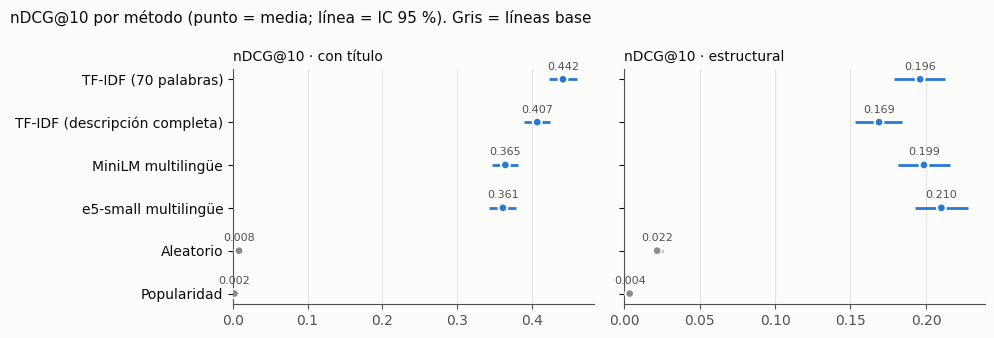

In [7]:
AZUL, GRIS, TINTA, TINTA2, FONDO = "#2a78d6", "#8d8c87", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": TINTA2,
                     "text.color": TINTA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def grafica_intervalos(res, metricas, titulo):
    orden = ev.bootstrap(res, metricas[0])["media"].sort_values().index
    fig, ejes = plt.subplots(1, len(metricas), figsize=(5 * len(metricas), 3.4), sharey=True)
    for ax, m in zip(np.atleast_1d(ejes), metricas):
        b = ev.bootstrap(res, m).loc[orden]
        y = np.arange(len(b))
        color = [GRIS if i in ("aleatorio", "popularidad") else AZUL for i in b.index]
        ax.hlines(y, b.ic_inf, b.ic_sup, color=color, lw=2)
        ax.scatter(b.media, y, color=color, s=40, zorder=3, edgecolor=FONDO, linewidth=1.5)
        for yi, v in zip(y, b.media): ax.annotate(f"{v:.3f}", (v, yi), xytext=(0, 7), textcoords="offset points",
                                                  ha="center", fontsize=8, color=TINTA2)
        ax.set_yticks(y, [NOMBRES[i] for i in b.index]); ax.set_title(METRICAS[m], fontsize=10, loc="left")
        ax.set_xlim(left=0); ax.grid(axis="x", color="#e4e3df", lw=0.8); ax.set_axisbelow(True)
    fig.suptitle(titulo, x=0.01, ha="left", fontsize=11)
    fig.tight_layout(); plt.show()

grafica_intervalos(res, ["ndcg_titulo", "ndcg_estructural"],
                   "nDCG@10 por método (punto = media; línea = IC 95 %). Gris = líneas base")

### Ejemplos: qué recomienda cada método

In [8]:
def ejemplos(i, metodos=("tfidf", "minilm", "e5"), n=5):
    f = consultas.iloc[i]
    rel_t = etiquetas.de(f)[0]
    print(f"Perfil: {perfiles[i]}")
    for m in metodos:
        print(f"  {NOMBRES[m]}:")
        for j in tops[m][i][:n]: print(f"     [{rel_t[j]}] {df['title'].iloc[j]}")
for i in [0, 7, 21]: ejemplos(i); print()

Perfil: lpn licensed practical nurse. Skills: Health Care Provider. Experience level: entry level.
  TF-IDF (70 palabras):
     [1] Licensed Practical Nurse
     [2] PRN/PART TIME LPN Licensed Practical Nurse
     [0] Licensed Practical Nurse - LPN - Nights
     [1] Licensed Practical Nurse
     [1] Licensed Practical Nurse (LPN) - Full Time
  MiniLM multilingüe:
     [2] LPN Licensed Practical Nurse
     [1] Licensed Practical Nurse LPN
     [2] LPN Licensed Practical Nurse
     [1] Licensed Practical Nurse LPN
     [2] LPN Licensed Practical Nurse
  e5-small multilingüe:
     [1] Licensed Practical Nurse (LPN)
     [1] Licensed Practical Nurse- (LPN)
     [0] icensed practical nurse (LPN)
     [2] LPN Licensed Practical Nurse
     [1] Registered Nurse (RN) Licensed Practical Nurse (LPN)

Perfil: systems engineer. Skills: Information Technology. Experience level: mid-senior level.
  TF-IDF (70 palabras):
     [0] Product Manager
     [0] User Interface Designer / UI Designer
     [0] 

## 4. Prueba entre idiomas
Se traducen al español los primeros 200 perfiles y se repite la evaluación **con las mismas consultas y etiquetas**.
El catálogo sigue en inglés: así se simula a un usuario mexicano frente a vacantes en inglés.

In [9]:
t0 = time.time()
sub = consultas.iloc[:N_IDIOMAS]
perfiles_es = ev.traducir(perfiles[:N_IDIOMAS], "en", "es")
print(f"Traducción: {time.time()-t0:.0f} s")
for en, es in list(zip(perfiles, perfiles_es))[:5]: print(f"  EN: {en}\n  ES: {es}\n")

Traducción: 19 s
  EN: lpn licensed practical nurse. Skills: Health Care Provider. Experience level: entry level.
  ES: lpn licenciada enfermera práctica. Habilidades: Proveedor de atención de salud. Nivel de experiencia: nivel de entrada.

  EN: mechanical engineer. Skills: Engineering. Experience level: entry level.
  ES: ingeniero mecánico. Habilidades: Ingeniería. Nivel de experiencia: nivel de entrada.

  EN: product manager. Skills: Product Management. Experience level: mid-senior level.
  ES: gerente de productos. Habilidades: Gestión de productos. Nivel de experiencia: nivel medio-senior.

  EN: mechanical engineer. Skills: Engineering. Experience level: associate.
  ES: Ingeniero mecánico. Habilidades: Ingeniería. Nivel de experiencia: asociado.

  EN: program manager. Skills: Information Technology, Project Management. Experience level: mid-senior level.
  ES: gerente de programa. Habilidades: Tecnología de la Información, Gestión de Proyectos. Nivel de experiencia: nivel med

In [10]:
tops_en = {k: v[:N_IDIOMAS] for k, v in tops.items()}
tops_es = {"aleatorio": tops["aleatorio"][:N_IDIOMAS], "popularidad": tops["popularidad"][:N_IDIOMAS]}
for clave in ["tfidf", "tfidf_completo", "minilm", "e5"]:
    r = ev.Ranker(clave); tops_es[clave] = ev.tops_modelo(r, perfiles_es, sub, grupo); del r; gc.collect()
res_en = ev.evaluar(tops_en, sub, etiquetas)
res_es = ev.evaluar(tops_es, sub, etiquetas)

filas = []
for m in ["ndcg_titulo", "ndcg_estructural"]:
    ben, bes = ev.bootstrap(res_en, m), ev.bootstrap(res_es, m)
    for k in NOMBRES:
        d = res_es.query("metodo == @k")[m].to_numpy() - res_en.query("metodo == @k")[m].to_numpy()
        filas.append({"métrica": METRICAS[m], "método": NOMBRES[k], "inglés": ben.loc[k, "media"],
                      "español": bes.loc[k, "media"], "español IC 95 %": f"[{bes.loc[k,'ic_inf']:.3f}, {bes.loc[k,'ic_sup']:.3f}]",
                      "cambio %": 100 * np.nanmean(d) / ben.loc[k, "media"] if ben.loc[k, "media"] > 0 else np.nan})
idiomas = pd.DataFrame(filas)
idiomas

,métrica,método,inglés,español,español IC 95 %,cambio %
0,nDCG@10 · con título,Aleatorio,0.008,0.008,"[0.005, 0.012]",0.000
1,nDCG@10 · con título,Popularidad,0.004,0.004,"[0.001, 0.008]",0.000
2,nDCG@10 · con título,TF-IDF (70 palabras),0.432,0.016,"[0.005, 0.030]",-96.336
3,nDCG@10 · con título,TF-IDF (descripción completa),0.388,0.009,"[0.003, 0.018]",-97.631
4,nDCG@10 · con título,MiniLM multilingüe,0.376,0.094,"[0.072, 0.117]",-75.030
5,nDCG@10 · con título,e5-small multilingüe,0.368,0.165,"[0.135, 0.195]",-55.269
6,nDCG@10 · estructural,Aleatorio,0.021,0.021,"[0.013, 0.032]",0.000
7,nDCG@10 · estructural,Popularidad,0.006,0.006,"[0.002, 0.011]",0.000
8,nDCG@10 · estructural,TF-IDF (70 palabras),0.234,0.013,"[0.004, 0.027]",-94.245
9,nDCG@10 · estructural,TF-IDF (descripción completa),0.181,0.009,"[0.002, 0.019]",-94.825


In [11]:
# ¿Cuánto del perfil en español reconoce el vocabulario (inglés) de TF-IDF? Explica por qué no cae a cero.
import pickle
vec = pickle.load(open(ev.em.PROCESADO / "vectorizador_tfidf.pkl", "rb"))
analizar = vec.build_analyzer(); vocab = vec.vocabulary_
cobertura = [np.mean([t in vocab for t in analizar(p)]) if analizar(p) else 0 for p in perfiles_es]
print(f"Términos del perfil en español que existen en el vocabulario de TF-IDF: mediana {np.median(cobertura):.0%}")
print("Ejemplos de términos reconocidos:", sorted({t for p in perfiles_es[:40] for t in analizar(p) if t in vocab and ' ' not in t})[:25])

Términos del perfil en español que existen en el vocabulario de TF-IDF: mediana 29%
Ejemplos de términos reconocidos: ['al', 'alto', 'asistente', 'atención', 'business', 'chef', 'cliente', 'cocina', 'coordinador', 'dental', 'en', 'end', 'especialista', 'experiencia', 'fiscal', 'general', 'habilidades', 'información', 'la', 'lpn', 'management', 'manager', 'marketing', 'nivel', 'otros']


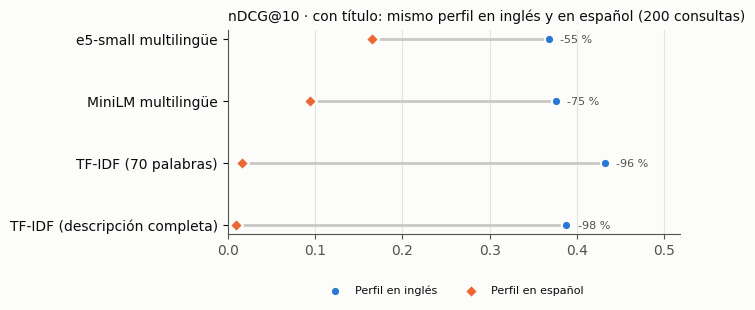

In [12]:
NARANJA = "#eb6834"
m = "ndcg_titulo"
d = idiomas[idiomas["métrica"] == METRICAS[m]].set_index("método").loc[[NOMBRES[k] for k in ["tfidf_completo", "tfidf", "minilm", "e5"]]]
fig, ax = plt.subplots(figsize=(7, 3.3))
y = np.arange(len(d))
ax.hlines(y, d["español"], d["inglés"], color="#c9c8c3", lw=2)
ax.scatter(d["inglés"], y, color=AZUL, s=45, zorder=3, edgecolor=FONDO, linewidth=1.5, label="Perfil en inglés")
ax.scatter(d["español"], y, color=NARANJA, s=45, zorder=3, edgecolor=FONDO, linewidth=1.5, marker="D", label="Perfil en español")
for yi, (en, es, c) in enumerate(zip(d["inglés"], d["español"], d["cambio %"])):
    ax.annotate(f"{c:+.0f} %", (max(en, es), yi), xytext=(8, -3), textcoords="offset points", fontsize=8, color=TINTA2)
ax.set_yticks(y, d.index); ax.set_xlim(0, max(d["inglés"].max(), d["español"].max()) * 1.2)
ax.grid(axis="x", color="#e4e3df", lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8)
ax.set_title(f"{METRICAS[m]}: mismo perfil en inglés y en español ({N_IDIOMAS} consultas)", loc="left", fontsize=10)
fig.tight_layout(); plt.show()

### 4b. Experimento adicional: traducir el perfil al inglés antes de buscar
*Se agregó después de ver la caída en español; se reporta como tal.* La app puede traducir lo que escribe el usuario
(es → en, `Helsinki-NLP/opus-mt-es-en`) y buscar con el perfil traducido. Aquí el español de entrada es el de la
prueba anterior, así que es un viaje de ida y vuelta (en → es → en): puede recuperar palabras del original mejor que
el español de una persona real, de modo que el resultado es optimista.

In [13]:
t0 = time.time()
perfiles_ida_vuelta = ev.traducir(perfiles_es, "es", "en")
print(f"Traducción es → en: {time.time()-t0:.0f} s")
for es, en2 in list(zip(perfiles_es, perfiles_ida_vuelta))[:4]: print(f"  ES: {es}"); print(f"  → EN: {en2}")
tops_iv = {}
for clave in ["tfidf", "minilm", "e5"]:
    r = ev.Ranker(clave); tops_iv[clave] = ev.tops_modelo(r, perfiles_ida_vuelta, sub, grupo); del r; gc.collect()
res_iv = ev.evaluar(tops_iv, sub, etiquetas)
filas = []
for m in ["ndcg_titulo", "ndcg_estructural"]:
    ben, bes, biv = ev.bootstrap(res_en, m), ev.bootstrap(res_es, m), ev.bootstrap(res_iv, m)
    for k in ["tfidf", "minilm", "e5"]:
        filas.append({"métrica": METRICAS[m], "método": NOMBRES[k], "inglés": ben.loc[k, "media"],
                      "español directo": bes.loc[k, "media"], "español → inglés": biv.loc[k, "media"],
                      "IC 95 % (es → en)": f"[{biv.loc[k,'ic_inf']:.3f}, {biv.loc[k,'ic_sup']:.3f}]"})
traduccion = pd.DataFrame(filas)
traduccion

Traducción es → en: 16 s
  ES: lpn licenciada enfermera práctica. Habilidades: Proveedor de atención de salud. Nivel de experiencia: nivel de entrada.
  → EN: lpn graduate practical nurse. Skills: Health care provider. Experience level: entry level.
  ES: ingeniero mecánico. Habilidades: Ingeniería. Nivel de experiencia: nivel de entrada.
  → EN: mechanical engineer. Skills: Engineering. Level of experience: entrance level.
  ES: gerente de productos. Habilidades: Gestión de productos. Nivel de experiencia: nivel medio-senior.
  → EN: Product Manager. Skills: Product Management. Experience Level: Medium-Senior Level.
  ES: Ingeniero mecánico. Habilidades: Ingeniería. Nivel de experiencia: asociado.
  → EN: Mechanical engineer. Skills: Engineering. Experience level: Associate.


,métrica,método,inglés,español directo,español → inglés,IC 95 % (es → en)
0,nDCG@10 · con título,TF-IDF (70 palabras),0.432,0.016,0.299,"[0.257, 0.341]"
1,nDCG@10 · con título,MiniLM multilingüe,0.376,0.094,0.315,"[0.275, 0.355]"
2,nDCG@10 · con título,e5-small multilingüe,0.368,0.165,0.323,"[0.284, 0.362]"
3,nDCG@10 · estructural,TF-IDF (70 palabras),0.234,0.013,0.175,"[0.139, 0.211]"
4,nDCG@10 · estructural,MiniLM multilingüe,0.222,0.115,0.188,"[0.149, 0.226]"
5,nDCG@10 · estructural,e5-small multilingüe,0.223,0.119,0.208,"[0.170, 0.248]"


In [14]:
# Diferencias pareadas en las 200 consultas con el perfil traducido es → en
ambos = pd.concat([res_iv, res_es.assign(metodo=res_es["metodo"] + "_es")])
for a, b in [("e5", "tfidf"), ("e5", "minilm"), ("e5", "e5_es")]:
    d, lo, hi, p = ev.diferencia_pareada(ambos, "ndcg_titulo", a, b)
    print(f"nDCG@10 con título · {a} (es→en) − {b}: {d:+.3f} [{lo:+.3f}, {hi:+.3f}] · P(a > b) = {p:.3f}")

nDCG@10 con título · e5 (es→en) − tfidf: +0.024 [-0.021, +0.067] · P(a > b) = 0.857
nDCG@10 con título · e5 (es→en) − minilm: +0.008 [-0.025, +0.042] · P(a > b) = 0.695
nDCG@10 con título · e5 (es→en) − e5_es: +0.158 [+0.126, +0.192] · P(a > b) = 1.000


## 5. Conclusiones y modelo elegido

**1. Todos los modelos le ganan por mucho a las líneas base.** Con perfiles en inglés, el nDCG@10 con título de los
cuatro métodos de texto está entre 0.36 y 0.44, contra 0.008 del azar y 0.002 de la popularidad. Recomendar lo más visto
no sirve: las vacantes populares no tienen nada que ver con el perfil.

**2. En inglés, TF-IDF gana con las etiquetas de título, pero esa ventaja es en parte circular.** El perfil incluye el
puesto y la etiqueta 2 es "mismo puesto", así que coincidir palabra por palabra con el título premia a TF-IDF (0.442
contra 0.36 de los densos). Con la etiqueta **solo estructural**, que no mira el título, la ventaja desaparece: e5 queda
arriba (0.210 contra 0.196; diferencia +0.014, IC [+0.000, +0.028]), prácticamente un empate. Los ejemplos muestran
otro sesgo de la etiqueta: "System Engineer" frente a "systems engineer" o "LPN Licensed Practical Nurse" frente a
"Licensed Practical Nurse" cuentan como puestos distintos aunque sean el mismo, y eso castiga justo a los modelos que
entienden sinónimos.

**3. Recortar la descripción ayuda.** TF-IDF con título + 70 palabras supera a TF-IDF con la descripción completa en las
dos etiquetas (+0.034 y +0.027, P = 1.00): el final de los anuncios es texto genérico (beneficios, avisos legales) que mete ruido.

**4. En español, TF-IDF se desploma y los multilingües resisten a medias.** Con el mismo perfil traducido, TF-IDF cae
96 % (sobrevive solo por palabras compartidas como "manager" o "marketing"), MiniLM 75 % y e5 55 %. e5 es el mejor en
español (0.165 contra 0.094 de MiniLM).

**5. Traducir el perfil al inglés antes de buscar recupera casi todo** (experimento agregado después; resultado
optimista por ser ida y vuelta): e5 pasa de 0.165 a 0.323, cerca de su 0.368 en inglés. Con traducción, los tres
métodos quedan juntos (e5 0.323, MiniLM 0.315, TF-IDF 0.299; e5 − TF-IDF = +0.024, IC [−0.021, +0.067]).

**Decisión (regla fijada al inicio: mayor nDCG@10 con perfiles en español):** la app usa **multilingual-e5-small**, y
además **traduce al inglés lo que escribe el usuario** con MarianMT (es → en) antes de buscar. e5 es el mejor en español
directo y con traducción, y en inglés empata con TF-IDF en la etiqueta que no favorece a nadie. Si la traducción falla, e5
sigue funcionando directo en español, que es el escenario en que más le gana a TF-IDF.

**Limitaciones.** Las categorías de habilidad del dataset son amplias (35), así que el perfil sintético es más pobre que el
de una persona real; las etiquetas no unen sinónimos de puestos; el catálogo es de EE. UU.; la prueba entre idiomas usa
traducción automática, no español escrito por personas; y la ida y vuelta es optimista.

## 6. Guardar resultados para la app y la presentación

In [15]:
salida = ev.em.PROCESADO
res.assign(idioma="en").to_parquet(salida / "evaluacion_por_consulta.parquet")
idiomas.to_csv(salida / "evaluacion_idiomas.csv", index=False)
traduccion.to_csv(salida / "evaluacion_traduccion.csv", index=False)
tabla(res).to_csv(salida / "evaluacion_tabla.csv")
print("Guardado en", salida)

Guardado en /Users/leocarpio/Downloads/primera-chamba/datos/procesado
